In [1]:
#B1 FROM SCRATCH

In [2]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device", device)

BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MAX_EPOCHS = 20
PATIENCE = 5

NUM_CLASSES = 10

print("Batch_size", BATCH_SIZE)
print("Learning_rate", LEARNING_RATE)
print("Max_epochs", MAX_EPOCHS)

device cuda
Batch_size 32
Learning_rate 0.001
Max_epochs 20


In [3]:
dataset_trainval = datasets.OxfordIIITPet(root = "/content/data", split = "trainval", target_types = "category", download=True)
dataset_test = datasets.OxfordIIITPet(root = "/content/data", split = "test", target_types = "category", download=True)
print("download selesai")
print("jumlah gambar trainval :", len(dataset_trainval))
print("jumlah gambar test :", len(dataset_test))
print("label", dataset_trainval[0][1])

100%|██████████| 792M/792M [00:30<00:00, 25.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.7MB/s]


download selesai
jumlah gambar trainval : 3680
jumlah gambar test : 3669
label 0


In [4]:

class_names = [
    "Abyssinian",
    "american_bulldog",
    "american_pit_bull_terrier",
    "basset_hound",
    "beagle",
    "Bengal",
    "Birman",
    "Bombay",
    "boxer",
    "British_Shorthair",
    "Chihuahua",
    "Egyptian_Mau",
    "english_cocker_spaniel",
    "english_setter",
    "german_shorthaired",
    "great_pyrenees",
    "havanese",
    "japanese_chin",
    "keeshond",
    "leonberger",
    "Maine_Coon",
    "miniature_pinscher",
    "Newfoundland",
    "Persian",
    "pomeranian",
    "pug",
    "Ragdoll",
    "Russian_Blue",
    "saint_bernard",
    "Samoyed",
    "scottish_terrier",
    "shiba_inu",
    "Siamese",
    "Sphynx",
    "staffordshire_bull_terrier",
    "wheaten_terrier",
    "yorkshire_terrier"
]

selected_classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British_Shorthair",
    "american_bulldog",
    "american_pit_bull_terrier",
    "beagle",
    "boxer",
    "Chihuahua"
]

base_trainval = datasets.OxfordIIITPet(
    root="/content/data",
    split="trainval",
    target_types="category",
    download=True
)

base_test = datasets.OxfordIIITPet(
    root="/content/data",
    split="test",
    target_types="category",
    download=True
)

print("Jumlah kelas:", len(class_names))
print("Jumlah gambar trainval:", len(base_trainval))
print("Jumlah gambar test resmi:", len(base_test))

all_original_labels = (
    list(map(int, base_trainval._labels))
    + list(map(int, base_test._labels))
)

print("Contoh label:", all_original_labels[:10])


Jumlah kelas: 37
Jumlah gambar trainval: 3680
Jumlah gambar test resmi: 3669
Contoh label: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

selected_ids = {
    class_names.index(name): i
    for i, name in enumerate(selected_classes)
}

selected_indices = [
    i for i, label in enumerate(all_original_labels)
    if label in selected_ids
]

selected_labels = [
    selected_ids[all_original_labels[i]]
    for i in selected_indices
]

train_idx, remaining_idx = train_test_split(
    selected_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

remaining_labels = [
    selected_ids[all_original_labels[i]]
    for i in remaining_idx
]

val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_labels
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
print("Total:", len(train_idx) + len(val_idx) + len(test_idx))


Train: 1386
Validation: 297
Test: 298
Total: 1981


In [6]:

class PetSubset(Dataset):
    def __init__(self, base_dataset, indices, label_mapping):
        self.base_dataset = base_dataset
        self.indices = indices
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, original_label = self.base_dataset[
            self.indices[idx]
        ]

        new_label = self.label_mapping[int(original_label)]

        return image, new_label

train_base = ConcatDataset([
    datasets.OxfordIIITPet(
        root="/content/data",
        split="trainval",
        target_types="category",
        transform=train_transform
    ),
    datasets.OxfordIIITPet(
        root="/content/data",
        split="test",
        target_types="category",
        transform=train_transform
    )
])

eval_base = ConcatDataset([
    datasets.OxfordIIITPet(
        root="/content/data",
        split="trainval",
        target_types="category",
        transform=eval_transform
    ),
    datasets.OxfordIIITPet(
        root="/content/data",
        split="test",
        target_types="category",
        transform=eval_transform
    )
])

train_dataset = PetSubset(train_base, train_idx, selected_ids)
val_dataset = PetSubset(eval_base, val_idx, selected_ids)
test_dataset = PetSubset(eval_base, test_idx, selected_ids)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DataLoader siap.")
print("Jumlah batch training:", len(train_loader))
print("Jumlah batch validation:", len(val_loader))
print("Jumlah batch test:", len(test_loader))


DataLoader siap.
Jumlah batch training: 44
Jumlah batch validation: 10
Jumlah batch test: 10


In [7]:

model = models.resnet18(weights=None)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-2
)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Model:", device)


Total parameters: 11,181,642
Trainable parameters: 11,181,642
Model: cuda


In [8]:

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy


history = []
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
patience_counter = 0

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    epoch_start = time.time()

    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, criterion
    )

    epoch_duration = time.time() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_duration_seconds": epoch_duration
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Early stopping berdasarkan validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
        torch.save(best_state, "/content/b1_best_model.pth")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping aktif.")
        break

total_duration = time.time() - start_time

model.load_state_dict(best_state)

history_df = pd.DataFrame(history)
history_df.to_csv("/content/b1_training_log.csv", index=False)

print(f"\nTotal training time: {total_duration:.2f} detik")
print("Epoch yang dijalankan:", len(history))
print("Best validation loss:", round(best_val_loss, 4))


Epoch 01/20 | Train Loss: 2.3431 | Train Acc: 0.1775 | Val Loss: 2.3455 | Val Acc: 0.1987
Epoch 02/20 | Train Loss: 2.0822 | Train Acc: 0.2511 | Val Loss: 2.2391 | Val Acc: 0.2121
Epoch 03/20 | Train Loss: 2.0322 | Train Acc: 0.2821 | Val Loss: 3.0905 | Val Acc: 0.1987
Epoch 04/20 | Train Loss: 1.8990 | Train Acc: 0.3240 | Val Loss: 2.1171 | Val Acc: 0.2290
Epoch 05/20 | Train Loss: 1.8277 | Train Acc: 0.3456 | Val Loss: 2.0431 | Val Acc: 0.2929
Epoch 06/20 | Train Loss: 1.7667 | Train Acc: 0.3795 | Val Loss: 2.1674 | Val Acc: 0.3064
Epoch 07/20 | Train Loss: 1.7496 | Train Acc: 0.3867 | Val Loss: 1.7091 | Val Acc: 0.4209
Epoch 08/20 | Train Loss: 1.6275 | Train Acc: 0.4286 | Val Loss: 1.8578 | Val Acc: 0.3838
Epoch 09/20 | Train Loss: 1.5981 | Train Acc: 0.4380 | Val Loss: 1.7343 | Val Acc: 0.4108
Epoch 10/20 | Train Loss: 1.5950 | Train Acc: 0.4437 | Val Loss: 1.7146 | Val Acc: 0.4108
Epoch 11/20 | Train Loss: 1.5609 | Train Acc: 0.4596 | Val Loss: 1.6016 | Val Acc: 0.4545
Epoch 12/2

In [9]:

model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

test_macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=selected_classes,
    zero_division=0
))


Test Accuracy: 0.4966
Test Macro F1: 0.4752

Classification Report:
                           precision    recall  f1-score   support

               Abyssinian       0.47      0.23      0.31        30
                   Bengal       0.76      0.63      0.69        30
                   Birman       0.62      0.67      0.65        30
                   Bombay       0.54      0.93      0.68        28
        British_Shorthair       0.55      0.73      0.63        30
         american_bulldog       0.31      0.40      0.35        30
american_pit_bull_terrier       0.27      0.43      0.33        30
                   beagle       0.71      0.50      0.59        30
                    boxer       0.50      0.43      0.46        30
                Chihuahua       0.25      0.03      0.06        30

                 accuracy                           0.50       298
                macro avg       0.50      0.50      0.48       298
             weighted avg       0.50      0.50      0.47   

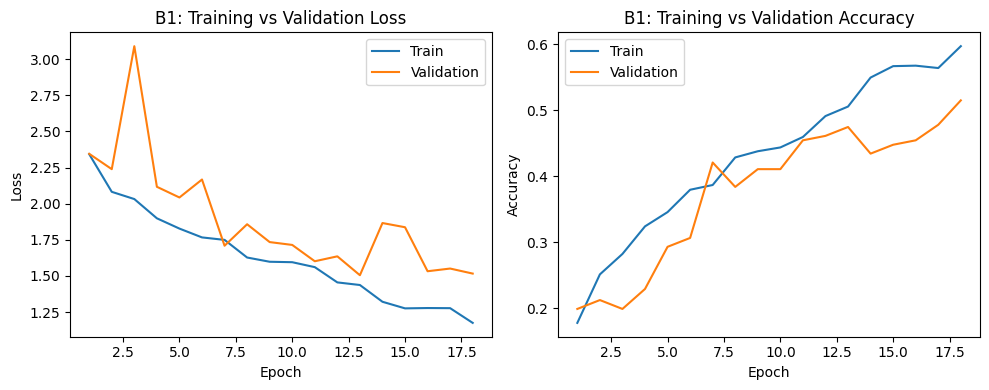

Metrik B1 tersimpan.


,experiment,architecture,pretrained,trainable_parameters,learning_rate,epochs_run,best_validation_loss,final_validation_accuracy,test_accuracy,test_macro_f1,training_duration_seconds,seed
0,B1_From_Scratch,ResNet18,False,11181642,0.001,18,1.504937,0.515152,0.496644,0.475247,279.31483,42


In [10]:

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("B1: Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["epoch"], history_df["train_accuracy"], label="Train")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("B1: Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame([{
    "experiment": "B1_From_Scratch",
    "architecture": "ResNet18",
    "pretrained": False,
    "trainable_parameters": trainable_params,
    "learning_rate": LEARNING_RATE,
    "epochs_run": len(history),
    "best_validation_loss": best_val_loss,
    "final_validation_accuracy": history_df["val_accuracy"].iloc[-1],
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "training_duration_seconds": total_duration,
    "seed": SEED
}])

summary.to_csv("/content/b1_metrics.csv", index=False)
summary.to_json("/content/b1_metrics.json", orient="records", indent=2)

print("Metrik B1 tersimpan.")
display(summary)


In [11]:
#B2 feature Extraction

In [12]:

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
for param in model.parameters():
    param.requires_grad = False
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
model = model.to(device)
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Learning rate:", 1e-3)
print("Jumlah kelas:", model.fc.out_features)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 122MB/s]


Total parameters: 11,181,642
Trainable parameters: 5,130
Learning rate: 0.001
Jumlah kelas: 10


In [13]:

from tqdm.auto import tqdm

MAX_EPOCHS = 20
PATIENCE = 5

history_B2 = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_B2 = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"B2 Epoch {epoch + 1}/{MAX_EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total
    history_B2["train_loss"].append(train_loss)
    history_B2["val_loss"].append(val_loss)
    history_B2["train_acc"].append(train_acc)
    history_B2["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_B2 = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping aktif.")
        break
model.load_state_dict(best_model_B2)

training_duration_B2 = time.time() - start_time

print("\nTraining B2 selesai.")
print("Epoch dijalankan:", len(history_B2["train_loss"]))
print(f"Durasi: {training_duration_B2:.2f} detik")
print(f"Best validation loss: {best_val_loss:.4f}")


B2 Epoch 1/20:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 1.4890 | Val Loss: 0.8413 | Train Acc: 0.5548 | Val Acc: 0.8249


B2 Epoch 2/20:   0%|          | 0/44 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 02 | Train Loss: 0.6997 | Val Loss: 0.4904 | Train Acc: 0.8651 | Val Acc: 0.9125


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>

AssertionError: can only test a child processTraceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 19 | Train Loss: 0.1656 | Val Loss: 0.2522 | Train Acc: 0.9538 | Val Acc: 0.9158


B2 Epoch 20/20:   0%|          | 0/44 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ecc3bd89080>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 20 | Train Loss: 0.1914 | Val Loss: 0.2608 | Train Acc: 0.9408 | Val Acc: 0.9091

Training B2 selesai.
Epoch dijalankan: 20
Durasi: 312.37 detik
Best validation loss: 0.2395


In [14]:
model.eval()

y_true_B2 = []
y_pred_B2 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true_B2.extend(labels.cpu().numpy())
        y_pred_B2.extend(predictions.cpu().numpy())

test_accuracy_B2 = accuracy_score(y_true_B2, y_pred_B2)
test_macro_f1_B2 = f1_score(
    y_true_B2,
    y_pred_B2,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy: {test_accuracy_B2:.4f}")
print(f"Test Macro F1: {test_macro_f1_B2:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_B2,
    y_pred_B2,
    zero_division=0
))


Test Accuracy: 0.9396
Test Macro F1: 0.9390

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.87      0.90        30
           1       0.94      0.97      0.95        30
           2       1.00      1.00      1.00        30
           3       0.93      1.00      0.97        28
           4       0.97      0.93      0.95        30
           5       0.90      0.87      0.88        30
           6       0.93      0.83      0.88        30
           7       0.94      0.97      0.95        30
           8       0.94      0.97      0.95        30
           9       0.94      1.00      0.97        30

    accuracy                           0.94       298
   macro avg       0.94      0.94      0.94       298
weighted avg       0.94      0.94      0.94       298



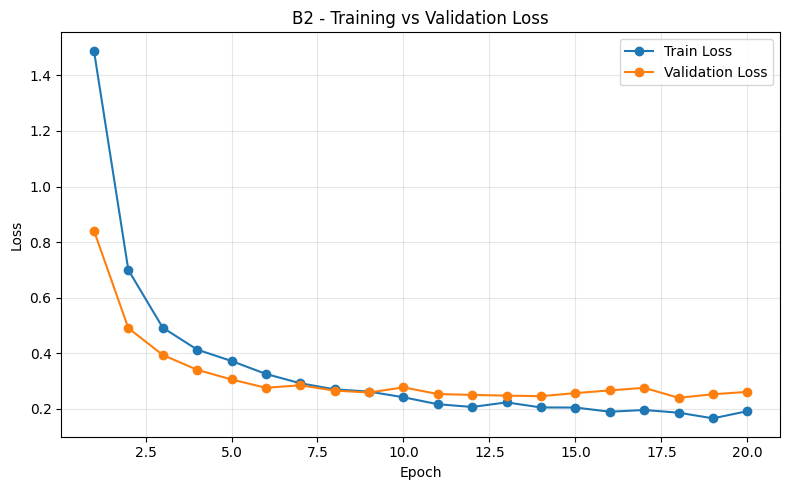

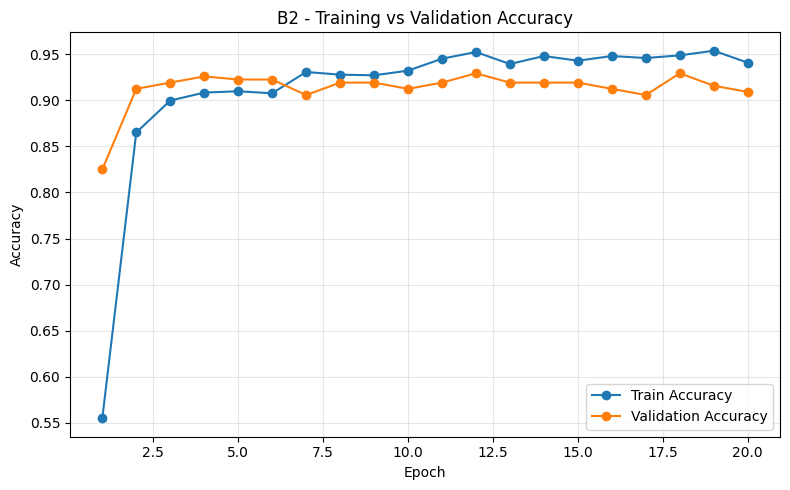

Grafik B2 tersimpan di /content/hasil_plot/


In [15]:
os.makedirs("/content/hasil_plot", exist_ok=True)

epochs = range(1, len(history_B2["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_B2["train_loss"], marker="o",
         label="Train Loss")
plt.plot(epochs, history_B2["val_loss"], marker="o",
         label="Validation Loss")
plt.title("B2 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B2_loss_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_B2["train_acc"], marker="o",
         label="Train Accuracy")
plt.plot(epochs, history_B2["val_acc"], marker="o",
         label="Validation Accuracy")
plt.title("B2 - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B2_accuracy_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Grafik B2 tersimpan di /content/hasil_plot/")


In [16]:

import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

model.eval()
y_true_B2 = []
y_pred_B2 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true_B2.extend(labels.cpu().numpy())
        y_pred_B2.extend(predictions.cpu().numpy())

test_acc_B2 = accuracy_score(y_true_B2, y_pred_B2)
test_macro_f1_B2 = f1_score(
    y_true_B2,
    y_pred_B2,
    average="macro",
    zero_division=0
)

metrics_B2 = pd.DataFrame([{
    "Experiment": "B2",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": sum(
        p.numel() for p in model.parameters() if p.requires_grad
    ),
    "Learning Rate": 1e-3,
    "Epochs": len(history_B2),
    "Best Validation Loss": best_val_loss,
    "Test Accuracy": test_acc_B2,
    "Test Macro F1": test_macro_f1_B2
}])

display(metrics_B2)
metrics_B2.to_csv("/content/B2_metrics.csv", index=False)
print("Metrics B2 berhasil disimpan!")


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,Learning Rate,Epochs,Best Validation Loss,Test Accuracy,Test Macro F1
0,B2,ResNet18,IMAGENET1K_V1,5130,0.001,4,0.239507,0.939597,0.938997


Metrics B2 berhasil disimpan!


In [17]:
#B3 Progressive Fine Tuning

In [18]:

model_B3 = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)
for param in model_B3.parameters():
    param.requires_grad = False
for param in model_B3.layer4.parameters():
    param.requires_grad = True
model_B3.fc = nn.Linear(model_B3.fc.in_features, 10)
model_B3 = model_B3.to(device)
criterion_B3 = nn.CrossEntropyLoss()

optimizer_B3 = torch.optim.AdamW([
    {"params": model_B3.layer4.parameters(), "lr": 1e-4},
    {"params": model_B3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

trainable_params_B3 = sum(
    p.numel() for p in model_B3.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable_params_B3:,}")
print("LR layer4: 1e-4 | LR fc: 1e-3")


Trainable parameters: 8,398,858
LR layer4: 1e-4 | LR fc: 1e-3


In [19]:


history_B3 = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

best_val_loss_B3 = float("inf")
best_model_state_B3 = copy.deepcopy(model_B3.state_dict())
patience_counter_B3 = 0
start_time_B3 = time.time()

for epoch in range(MAX_EPOCHS):
    model_B3.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_B3.zero_grad()
        outputs = model_B3(images)
        loss = criterion_B3(outputs, labels)
        loss.backward()
        optimizer_B3.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model_B3.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_B3(images)
            loss = criterion_B3(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history_B3["train_loss"].append(train_loss)
    history_B3["val_loss"].append(val_loss)
    history_B3["train_acc"].append(train_acc)
    history_B3["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss_B3:
        best_val_loss_B3 = val_loss
        best_model_state_B3 = copy.deepcopy(model_B3.state_dict())
        patience_counter_B3 = 0
    else:
        patience_counter_B3 += 1

    if patience_counter_B3 >= PATIENCE:
        print("Early stopping.")
        break

model_B3.load_state_dict(best_model_state_B3)
duration_B3 = time.time() - start_time_B3

print(f"Durasi: {duration_B3:.2f} detik")


Epoch 1/20 | Train Loss: 0.8790 | Train Acc: 0.7569 | Val Loss: 0.2311 | Val Acc: 0.9226
Epoch 2/20 | Train Loss: 0.2375 | Train Acc: 0.9315 | Val Loss: 0.2535 | Val Acc: 0.9293
Epoch 3/20 | Train Loss: 0.1431 | Train Acc: 0.9646 | Val Loss: 0.2363 | Val Acc: 0.9360
Epoch 4/20 | Train Loss: 0.1014 | Train Acc: 0.9740 | Val Loss: 0.2533 | Val Acc: 0.9226
Epoch 5/20 | Train Loss: 0.0684 | Train Acc: 0.9812 | Val Loss: 0.2606 | Val Acc: 0.9293
Epoch 6/20 | Train Loss: 0.0401 | Train Acc: 0.9921 | Val Loss: 0.2558 | Val Acc: 0.9259
Early stopping.
Durasi: 78.81 detik


In [20]:

logs_B3 = pd.DataFrame(history_B3)
logs_B3.index += 1
logs_B3.index.name = "Epoch"

display(logs_B3)
logs_B3.to_csv("/content/B3_training_logs.csv")


,train_loss,val_loss,train_acc,val_acc
Epoch,,,,
1,0.878963,0.231087,0.756854,0.922559
2,0.237478,0.253495,0.931457,0.929293
3,0.143113,0.236296,0.964646,0.936027
4,0.101385,0.253319,0.974026,0.922559
5,0.068410,0.260606,0.981241,0.929293
6,0.040052,0.255781,0.992063,0.925926


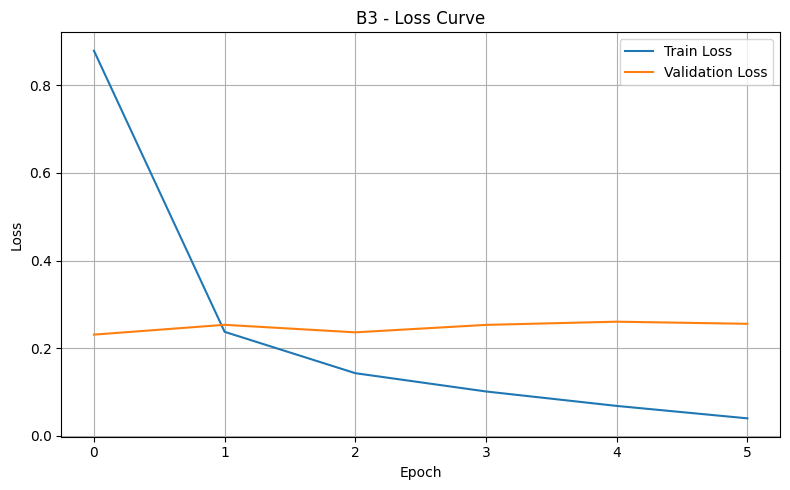

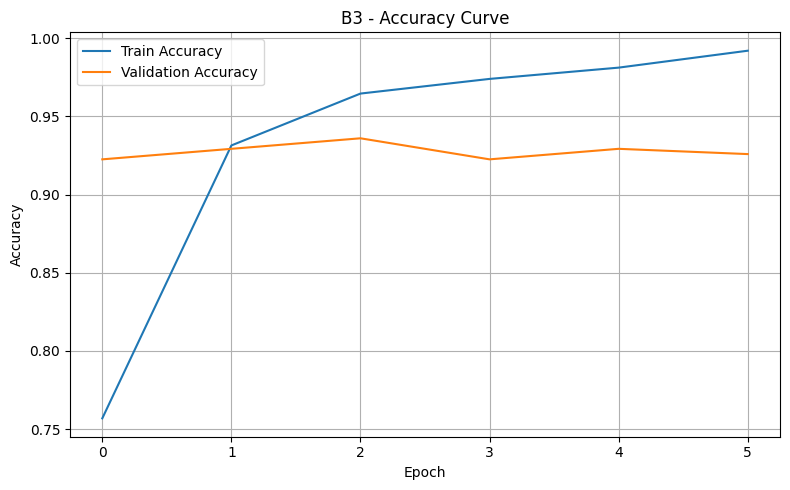

In [21]:

os.makedirs("/content/hasil_plot", exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(history_B3["train_loss"], label="Train Loss")
plt.plot(history_B3["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("B3 - Loss Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B3_loss_curve.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_B3["train_acc"], label="Train Accuracy")
plt.plot(history_B3["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("B3 - Accuracy Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B3_accuracy_curve.png", dpi=300)
plt.show()


In [22]:


model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)

from sklearn.metrics import accuracy_score, f1_score

model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)

model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)


model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)

from sklearn.metrics import accuracy_score, f1_score

model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)

from sklearn.metrics import accuracy_score, f1_score

model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)

from sklearn.metrics import accuracy_score, f1_score

model_B3.eval()
y_true_B3, y_pred_B3 = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model_B3(images.to(device))
        y_pred_B3.extend(outputs.argmax(1).cpu().numpy())
        y_true_B3.extend(labels.numpy())

test_acc_B3 = accuracy_score(y_true_B3, y_pred_B3)
test_macro_f1_B3 = f1_score(
    y_true_B3, y_pred_B3,
    average="macro", zero_division=0
)

metrics_B3 = pd.DataFrame([{
    "Experiment": "B3",
    "Architecture": "ResNet18",
    "Pretrained Weights": "IMAGENET1K_V1",
    "Trainable Parameters": trainable_params_B3,
    "LR layer4": 1e-4,
    "LR fc": 1e-3,
    "Epochs": len(history_B3["train_loss"]),
    "Duration (seconds)": round(duration_B3, 2),
    "Best Validation Loss": best_val_loss_B3,
    "Final Validation Accuracy": history_B3["val_acc"][-1],
    "Test Accuracy": test_acc_B3,
    "Test Macro F1": test_macro_f1_B3
}])

display(metrics_B3)
metrics_B3.to_csv("/content/B3_metrics.csv", index=False)


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


,Experiment,Architecture,Pretrained Weights,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Final Validation Accuracy,Test Accuracy,Test Macro F1
0,B3,ResNet18,IMAGENET1K_V1,8398858,0.0001,0.001,6,78.81,0.231087,0.925926,0.922819,0.921611


In [23]:
#B4 Augmentasi

In [24]:

transform_B4_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
transform_B4_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_B4_eval = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def create_B4_loaders(use_augmentation):
    train_transform_B4 = (
        transform_B4_aug if use_augmentation
        else transform_B4_no_aug
    )

    train_base_B4 = ConcatDataset([
        datasets.OxfordIIITPet(
            root="/content/data",
            split="trainval",
            target_types="category",
            transform=train_transform_B4
        ),
        datasets.OxfordIIITPet(
            root="/content/data",
            split="test",
            target_types="category",
            transform=train_transform_B4
        )
    ])

    eval_base_B4 = ConcatDataset([
        datasets.OxfordIIITPet(
            root="/content/data",
            split="trainval",
            target_types="category",
            transform=transform_B4_eval
        ),
        datasets.OxfordIIITPet(
            root="/content/data",
            split="test",
            target_types="category",
            transform=transform_B4_eval
        )
    ])

    train_ds = PetSubset(train_base_B4, train_idx, selected_ids)
    val_ds = PetSubset(eval_base_B4, val_idx, selected_ids)
    test_ds = PetSubset(eval_base_B4, test_idx, selected_ids)

    train_gen = torch.Generator().manual_seed(SEED)

    loaders = {
        "train": DataLoader(
            train_ds, batch_size=BATCH_SIZE, shuffle=True,
            num_workers=2, pin_memory=torch.cuda.is_available(),
            generator=train_gen
        ),
        "val": DataLoader(
            val_ds, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=2, pin_memory=torch.cuda.is_available()
        ),
        "test": DataLoader(
            test_ds, batch_size=BATCH_SIZE, shuffle=False,
            num_workers=2, pin_memory=torch.cuda.is_available()
        )
    }
    return loaders

print("DataLoader B4 siap dibuat.")


DataLoader B4 siap dibuat.


In [25]:

def run_B4_experiment(use_augmentation):
    label = "B4_Augmentation" if use_augmentation else "B4_No_Augmentation"
    loaders = create_B4_loaders(use_augmentation)
    model_exp = models.resnet18(
        weights=models.ResNet18_Weights.IMAGENET1K_V1
    )

    for param in model_exp.parameters():
        param.requires_grad = False

    for param in model_exp.layer4.parameters():
        param.requires_grad = True

    model_exp.fc = nn.Linear(model_exp.fc.in_features, NUM_CLASSES)
    model_exp = model_exp.to(device)

    criterion_exp = nn.CrossEntropyLoss()
    optimizer_exp = torch.optim.AdamW([
        {"params": model_exp.layer4.parameters(), "lr": 1e-4},
        {"params": model_exp.fc.parameters(), "lr": 1e-3}
    ], weight_decay=1e-2)

    history_exp = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_loss = float("inf")
    best_state = copy.deepcopy(model_exp.state_dict())
    patience_count = 0
    start = time.time()

    for epoch in range(20):
        model_exp.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0

        for images, labels in loaders["train"]:
            images, labels = images.to(device), labels.to(device)

            optimizer_exp.zero_grad()
            outputs = model_exp(images)
            loss = criterion_exp(outputs, labels)
            loss.backward()
            optimizer_exp.step()

            train_loss_sum += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        model_exp.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in loaders["val"]:
                images, labels = images.to(device), labels.to(device)
                outputs = model_exp(images)
                loss = criterion_exp(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history_exp["train_loss"].append(train_loss)
        history_exp["val_loss"].append(val_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_acc"].append(val_acc)

        print(
            f"{label} | Epoch {epoch+1}/20 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model_exp.state_dict())
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= 5:
            print("Early stopping.")
            break

    model_exp.load_state_dict(best_state)
    duration = time.time() - start
    model_exp.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loaders["test"]:
            outputs = model_exp(images.to(device))
            y_pred.extend(outputs.argmax(1).cpu().numpy())
            y_true.extend(labels.numpy())

    test_acc = accuracy_score(y_true, y_pred)
    test_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    metrics = {
        "Experiment": label,
        "Augmentation": use_augmentation,
        "Trainable Parameters": sum(
            p.numel() for p in model_exp.parameters() if p.requires_grad
        ),
        "LR layer4": 1e-4,
        "LR fc": 1e-3,
        "Epochs": len(history_exp["train_loss"]),
        "Duration (seconds)": round(duration, 2),
        "Best Validation Loss": best_loss,
        "Best Validation Accuracy": max(history_exp["val_acc"]),
        "Test Accuracy": test_acc,
        "Test Macro F1": test_f1,
        "Final Train Accuracy": history_exp["train_acc"][-1],
        "Final Validation Accuracy": history_exp["val_acc"][-1]
    }

    return history_exp, metrics


In [26]:

history_B4_no_aug, metrics_B4_no_aug = run_B4_experiment(False)

history_B4_aug, metrics_B4_aug = run_B4_experiment(True)

metrics_B4 = pd.DataFrame([
    metrics_B4_no_aug,
    metrics_B4_aug
])

display(metrics_B4)
metrics_B4.to_csv("/content/B4_metrics.csv", index=False)


B4_No_Augmentation | Epoch 1/20 | Train Loss: 0.7267 | Train Acc: 0.7807 | Val Loss: 0.2401 | Val Acc: 0.9293
B4_No_Augmentation | Epoch 2/20 | Train Loss: 0.1146 | Train Acc: 0.9747 | Val Loss: 0.2609 | Val Acc: 0.9259
B4_No_Augmentation | Epoch 3/20 | Train Loss: 0.0442 | Train Acc: 0.9935 | Val Loss: 0.2081 | Val Acc: 0.9394
B4_No_Augmentation | Epoch 4/20 | Train Loss: 0.0303 | Train Acc: 0.9957 | Val Loss: 0.1976 | Val Acc: 0.9394
B4_No_Augmentation | Epoch 5/20 | Train Loss: 0.0110 | Train Acc: 1.0000 | Val Loss: 0.2119 | Val Acc: 0.9428
B4_No_Augmentation | Epoch 6/20 | Train Loss: 0.0071 | Train Acc: 1.0000 | Val Loss: 0.2146 | Val Acc: 0.9394
B4_No_Augmentation | Epoch 7/20 | Train Loss: 0.0052 | Train Acc: 1.0000 | Val Loss: 0.2091 | Val Acc: 0.9461
B4_No_Augmentation | Epoch 8/20 | Train Loss: 0.0037 | Train Acc: 1.0000 | Val Loss: 0.2160 | Val Acc: 0.9394
B4_No_Augmentation | Epoch 9/20 | Train Loss: 0.0030 | Train Acc: 1.0000 | Val Loss: 0.2128 | Val Acc: 0.9428
Early stop

,Experiment,Augmentation,Trainable Parameters,LR layer4,LR fc,Epochs,Duration (seconds),Best Validation Loss,Best Validation Accuracy,Test Accuracy,Test Macro F1,Final Train Accuracy,Final Validation Accuracy
0,B4_No_Augmentation,False,8398858,0.0001,0.001,9,80.59,0.197578,0.946128,0.936242,0.935875,1.000000,0.942761
1,B4_Augmentation,True,8398858,0.0001,0.001,8,107.25,0.213883,0.946128,0.949664,0.949849,0.992785,0.929293


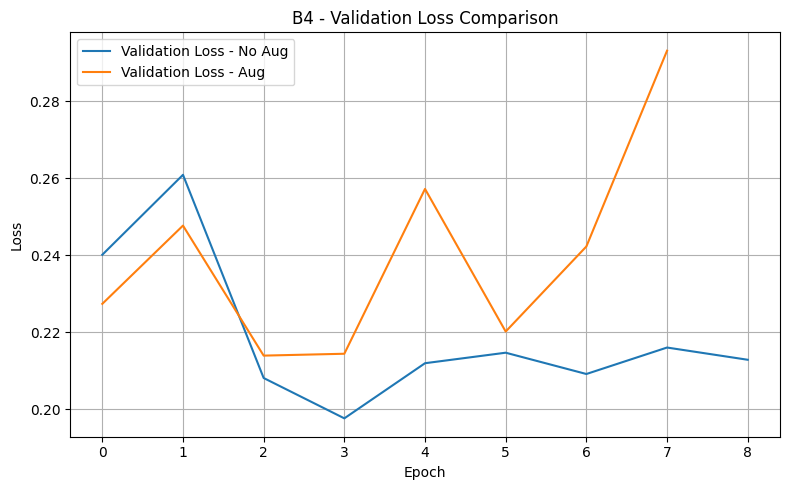

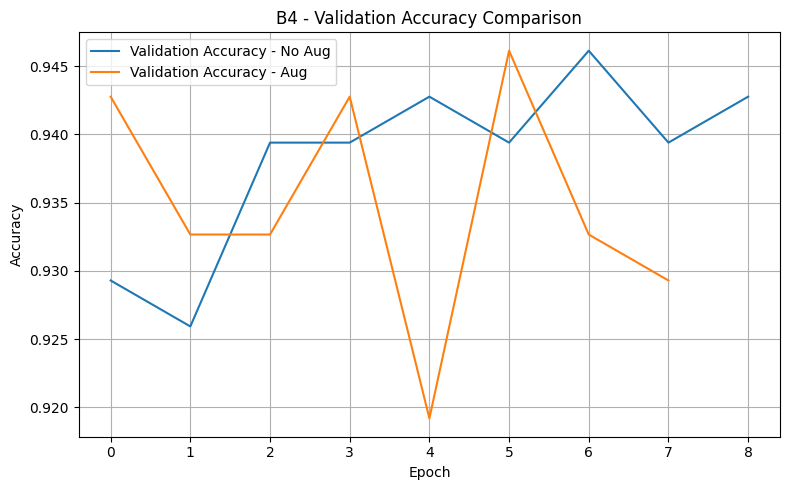

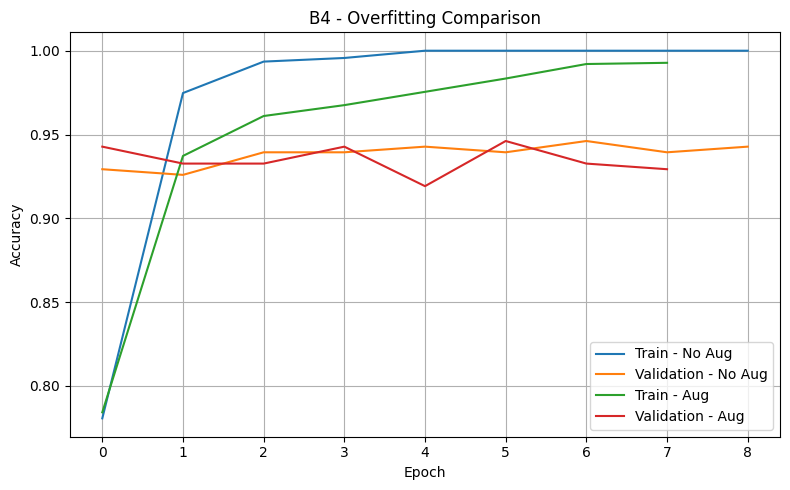

In [27]:

os.makedirs("/content/hasil_plot", exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(history_B4_no_aug["val_loss"], label="Validation Loss - No Aug")
plt.plot(history_B4_aug["val_loss"], label="Validation Loss - Aug")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("B4 - Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B4_loss_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_B4_no_aug["val_acc"], label="Validation Accuracy - No Aug")
plt.plot(history_B4_aug["val_acc"], label="Validation Accuracy - Aug")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("B4 - Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B4_accuracy_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_B4_no_aug["train_acc"], label="Train - No Aug")
plt.plot(history_B4_no_aug["val_acc"], label="Validation - No Aug")
plt.plot(history_B4_aug["train_acc"], label="Train - Aug")
plt.plot(history_B4_aug["val_acc"], label="Validation - Aug")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("B4 - Overfitting Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/hasil_plot/B4_overfitting_comparison.png", dpi=300)
plt.show()


In [28]:

logs_B4 = pd.concat([
    pd.DataFrame(history_B4_no_aug).assign(experiment="B4_No_Augmentation"),
    pd.DataFrame(history_B4_aug).assign(experiment="B4_With_Augmentation")
], ignore_index=True)

logs_B4.to_csv("/content/B4_training_logs.csv", index=False)

display(logs_B4)


,train_loss,val_loss,train_acc,val_acc,experiment
0,0.726704,0.240098,0.780664,0.929293,B4_No_Augmentation
1,0.114591,0.260882,0.974747,0.925926,B4_No_Augmentation
2,0.044227,0.208062,0.993506,0.939394,B4_No_Augmentation
3,0.030340,0.197578,0.995671,0.939394,B4_No_Augmentation
4,0.011010,0.211908,1.000000,0.942761,B4_No_Augmentation
5,0.007066,0.214639,1.000000,0.939394,B4_No_Augmentation
6,0.005191,0.209102,1.000000,0.946128,B4_No_Augmentation
7,0.003657,0.215983,1.000000,0.939394,B4_No_Augmentation
8,0.003012,0.212804,1.000000,0.942761,B4_No_Augmentation
9,0.804970,0.227339,0.784271,0.942761,B4_With_Augmentation


Total salah prediksi: 23 dari 298 gambar test

Pasangan salah paling sering (true -> pred):
  american bulldog -> boxer: 6x
  Abyssinian -> Bengal: 5x
  american pit bull terrier -> american bulldog: 2x
  american bulldog -> beagle: 2x
  american pit bull terrier -> boxer: 1x


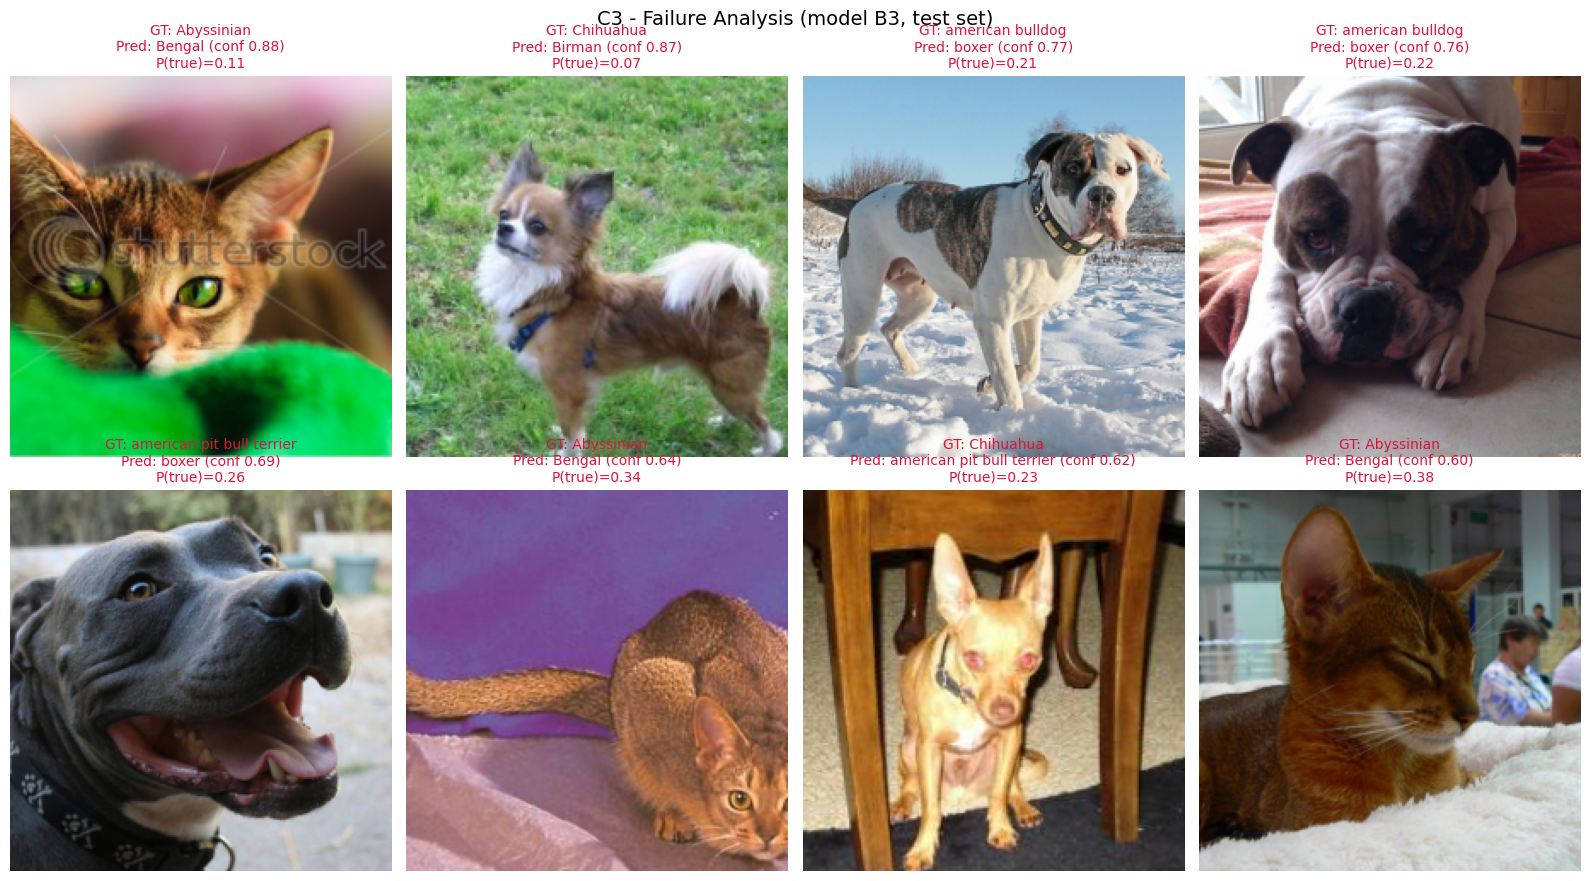

 test_position  dataset_index                true_label                pred_label  confidence_pred  prob_true_class
           127              1                Abyssinian                    Bengal           0.8829           0.1057
           285           4670                 Chihuahua                    Birman           0.8742           0.0749
           147           3874          american_bulldog                     boxer           0.7699           0.2069
           145           3822          american_bulldog                     boxer           0.7642           0.2233
            37           1983 american_pit_bull_terrier                     boxer           0.6854           0.2626
           107           1884                Abyssinian                    Bengal           0.6408           0.3426
           123           2379                 Chihuahua american_pit_bull_terrier           0.6224           0.2341
           174           1848                Abyssinian                 

In [29]:

from collections import Counter

os.makedirs("/content/hasil_plot", exist_ok=True)

MEAN = np.array([0.485, 0.456, 0.406])
STD  = np.array([0.229, 0.224, 0.225])
pretty = lambda n: n.replace("_", " ")

model_B3.eval()
rows, imgs = [], []
offset = 0
with torch.no_grad():
    for images, labels in test_loader:
        probs = torch.softmax(model_B3(images.to(device)), dim=1).cpu()
        conf, pred = probs.max(1)
        for j in range(len(labels)):
            if pred[j].item() != labels[j].item():
                rows.append({
                    "test_position": offset + j,
                    "dataset_index": int(test_idx[offset + j]),
                    "true_label": selected_classes[labels[j].item()],
                    "pred_label": selected_classes[pred[j].item()],
                    "confidence_pred": round(conf[j].item(), 4),
                    "prob_true_class": round(probs[j, labels[j]].item(), 4),
                })
                imgs.append(images[j].numpy())
        offset += len(labels)

df = pd.DataFrame(rows)
df["_img"] = range(len(df))
print(f"Total salah prediksi: {len(df)} dari {len(test_loader.dataset)} gambar test")
pairs = Counter(zip(df.true_label, df.pred_label)).most_common(5)
print("\nPasangan salah paling sering (true -> pred):")
for (t, p), c in pairs:
    print(f"  {pretty(t)} -> {pretty(p)}: {c}x")
df.drop(columns="_img").to_csv("/content/C3_misclassified.csv", index=False)

top = df.sort_values("confidence_pred", ascending=False).head(8)

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
    img = imgs[int(r["_img"])].transpose(1, 2, 0) * STD + MEAN
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(f"GT: {pretty(r.true_label)}\nPred: {pretty(r.pred_label)} "
                 f"(conf {r.confidence_pred:.2f})\nP(true)={r.prob_true_class:.2f}",
                 fontsize=10, color="crimson")
    ax.axis("off")
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
plt.suptitle("C3 - Failure Analysis (model B3, test set)", fontsize=14)
plt.tight_layout()
plt.savefig("/content/hasil_plot/C3_failure_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print(top.drop(columns="_img").to_string(index=False))
